# Project 3: Customer Churn / Sales Trend Analysis

## 1. Business Understanding

### Project Objective
The objective of this project is to analyze e-commerce sales data to identify monthly revenue trends, best-performing product categories, and valuable customers.

### Business Questions

1. Which months generate the highest revenue?
2. Which product categories perform best?
3. Who are the most valuable customers?
4. What percentage of revenue comes from the top 10% of customers?
5. What business recommendations can improve sales and customer retention?

In [ ]:
import numpy as np
import pandas as pd


rng = np.random.default_rng(42)
n = 2000

orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(
        rng.integers(0, 365, n), unit="D"
    ),
    "customer_id": rng.integers(1, 301, n),
    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n,
        p=[0.3, 0.35, 0.2, 0.15]
    ),
    "amount": rng.gamma(2.0, 600, n).round(2)
})

print("Dataset created successfully!")

Dataset created successfully!


In [3]:
orders.shape

(2000, 4)

In [4]:
orders.head()

,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


In [5]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   2000 non-null   datetime64[ns]
 1   customer_id  2000 non-null   int64         
 2   category     2000 non-null   object        
 3   amount       2000 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 62.6+ KB


In [6]:
orders.isnull().sum()

order_date     0
customer_id    0
category       0
amount         0
dtype: int64

In [7]:
orders.duplicated().sum()

np.int64(0)

In [8]:
orders.to_csv("ecommerce_orders.csv", index=False)

In [9]:
orders["month"] = orders["order_date"].dt.month

In [10]:
orders[["order_date", "month"]].head()

,order_date,month
0,2025-02-02,2
1,2025-10-10,10
2,2025-08-27,8
3,2025-06-10,6
4,2025-06-08,6


In [11]:
orders["month_name"] = orders["order_date"].dt.strftime("%B")

In [12]:

orders[["order_date", "month_name"]].head()

,order_date,month_name
0,2025-02-02,February
1,2025-10-10,October
2,2025-08-27,August
3,2025-06-10,June
4,2025-06-08,June


In [13]:
orders["weekday"] = orders["order_date"].dt.day_name()

orders[["order_date", "weekday"]].head()

,order_date,weekday
0,2025-02-02,Sunday
1,2025-10-10,Friday
2,2025-08-27,Wednesday
3,2025-06-10,Tuesday
4,2025-06-08,Sunday


In [14]:
orders["quarter"] = orders["order_date"].dt.quarter

orders[["order_date", "quarter"]].head()

,order_date,quarter
0,2025-02-02,1
1,2025-10-10,4
2,2025-08-27,3
3,2025-06-10,2
4,2025-06-08,2


In [15]:
orders.head()

,order_date,customer_id,category,amount,month,month_name,weekday,quarter
0,2025-02-02,264,Home,391.13,2,February,Sunday,1
1,2025-10-10,19,Fashion,2456.21,10,October,Friday,4
2,2025-08-27,120,Books,674.90,8,August,Wednesday,3
3,2025-06-10,138,Home,75.38,6,June,Tuesday,2
4,2025-06-08,240,Electronics,774.42,6,June,Sunday,2


In [16]:
monthly_revenue = orders.groupby("month_name")["amount"].sum()

print(monthly_revenue)

month_name
April        197310.20
August       179783.75
December     202148.21
February     232027.20
January      193341.87
July         221813.81
June         221889.83
March        206327.14
May          194090.49
November     191512.71
October      183418.13
September    180569.95
Name: amount, dtype: float64


In [17]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_revenue = (
    orders.groupby("month_name")["amount"]
    .sum()
    .reindex(month_order)
)

print(monthly_revenue)

month_name
January      193341.87
February     232027.20
March        206327.14
April        197310.20
May          194090.49
June         221889.83
July         221813.81
August       179783.75
September    180569.95
October      183418.13
November     191512.71
December     202148.21
Name: amount, dtype: float64


In [18]:
best_month = monthly_revenue.idxmax()
worst_month = monthly_revenue.idxmin()

print("Highest Revenue Month:", best_month)
print("Lowest Revenue Month:", worst_month)

Highest Revenue Month: February
Lowest Revenue Month: August


In [19]:
monthly_growth = monthly_revenue.pct_change() * 100

print("Monthly Revenue Growth (%):")
print(monthly_growth.round(2))

Monthly Revenue Growth (%):
month_name
January        NaN
February     20.01
March       -11.08
April        -4.37
May          -1.63
June         14.32
July         -0.03
August      -18.95
September     0.44
October       1.58
November      4.41
December      5.55
Name: amount, dtype: float64


In [20]:
monthly_growth = monthly_revenue.pct_change() * 100

print("Monthly Revenue Growth (%):")
print(monthly_growth.round(2))

Monthly Revenue Growth (%):
month_name
January        NaN
February     20.01
March       -11.08
April        -4.37
May          -1.63
June         14.32
July         -0.03
August      -18.95
September     0.44
October       1.58
November      4.41
December      5.55
Name: amount, dtype: float64


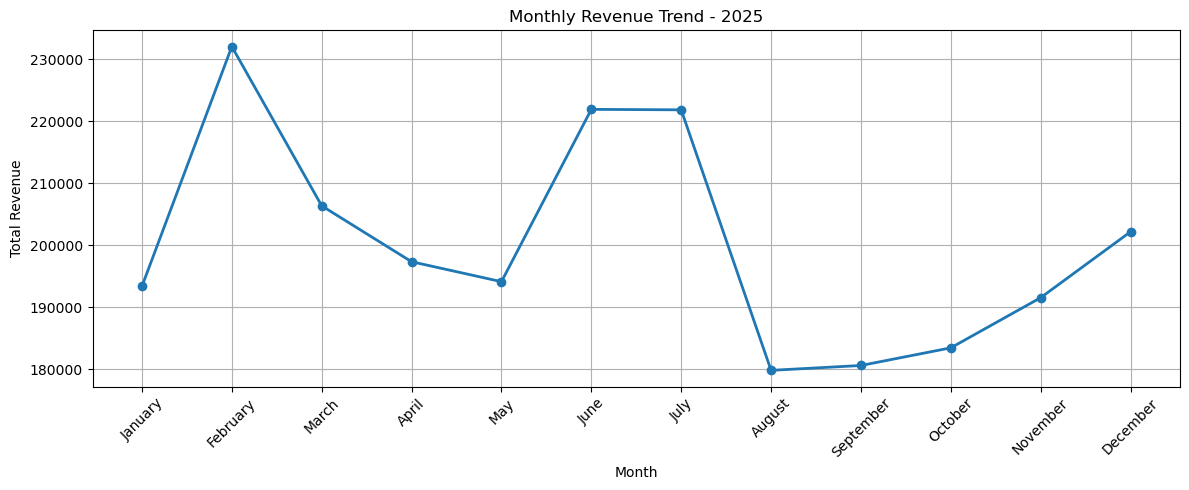

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
category_sales = orders.groupby("category")["amount"].sum()

print(category_sales.sort_values(ascending=False))

category
Fashion        853984.93
Electronics    722645.53
Home           464114.66
Books          363488.17
Name: amount, dtype: float64


In [23]:
category_analysis = orders.groupby("category")["amount"].agg(
    total_revenue="sum",
    average_order_value="mean",
    total_orders="count"
)

category_analysis = category_analysis.sort_values(
    by="total_revenue",
    ascending=False
)

print(category_analysis.round(2))

             total_revenue  average_order_value  total_orders
category                                                     
Fashion          853984.93              1219.98           700
Electronics      722645.53              1163.68           621
Home             464114.66              1218.15           381
Books            363488.17              1219.76           298


In [24]:
best_category = category_analysis["total_revenue"].idxmax()

print("Best Performing Category:", best_category)

Best Performing Category: Fashion


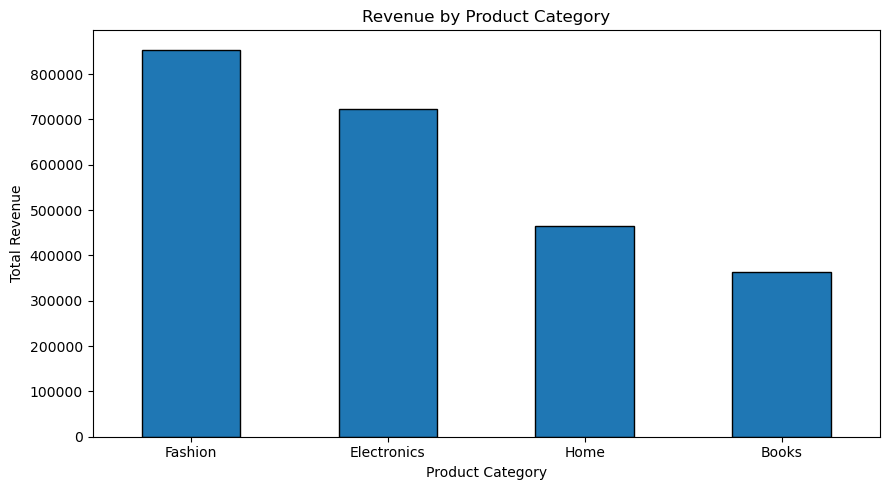

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

category_analysis["total_revenue"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
monthly_category = pd.pivot_table(
    orders,
    values="amount",
    index="month_name",
    columns="category",
    aggfunc="sum"
)

monthly_category = monthly_category.reindex(month_order)

print(monthly_category.round(2))

category       Books  Electronics   Fashion      Home
month_name                                           
January     29186.89     62841.89  64665.99  36647.10
February    34034.13     53564.89  86123.31  58304.87
March       27843.58     58055.95  75138.67  45288.94
April       26593.72     83335.56  57057.72  30323.20
May         34425.63     57219.16  68569.90  33875.80
June        32936.76     60037.00  85598.09  43317.98
July        35582.36     72649.65  72647.96  40933.84
August      32550.65     56690.46  71251.54  19291.10
September   21824.73     60388.56  60231.75  38124.91
October     23728.54     48799.72  70978.87  39911.00
November    35826.81     51641.63  65122.45  38921.82
December    28954.37     57421.06  76598.68  39174.10


In [27]:
customer_spending = orders.groupby("customer_id")["amount"].sum()

customer_spending = customer_spending.sort_values(
    ascending=False
)

print(customer_spending.head(10))

customer_id
226    18140.15
51     18126.28
53     17994.36
131    17639.25
185    17222.49
282    17161.00
121    16564.87
98     15351.48
255    15313.47
136    15265.80
Name: amount, dtype: float64


In [28]:
top_customer = customer_spending.idxmax()
top_customer_amount = customer_spending.max()

print("Top Customer ID:", top_customer)
print("Total Spending:", round(top_customer_amount, 2))

Top Customer ID: 226
Total Spending: 18140.15


In [29]:
total_revenue = customer_spending.sum()

top_10_count = int(len(customer_spending) * 0.10)

top_10_customers = customer_spending.head(top_10_count)

top_10_revenue = top_10_customers.sum()

top_10_percentage = (top_10_revenue / total_revenue) * 100

print("Total Customers:", len(customer_spending))
print("Top 10% Customers:", top_10_count)
print("Revenue from Top 10%:", round(top_10_revenue, 2))
print("Revenue Contribution:", round(top_10_percentage, 2), "%")

Total Customers: 300
Top 10% Customers: 30
Revenue from Top 10%: 455331.97
Revenue Contribution: 18.94 %


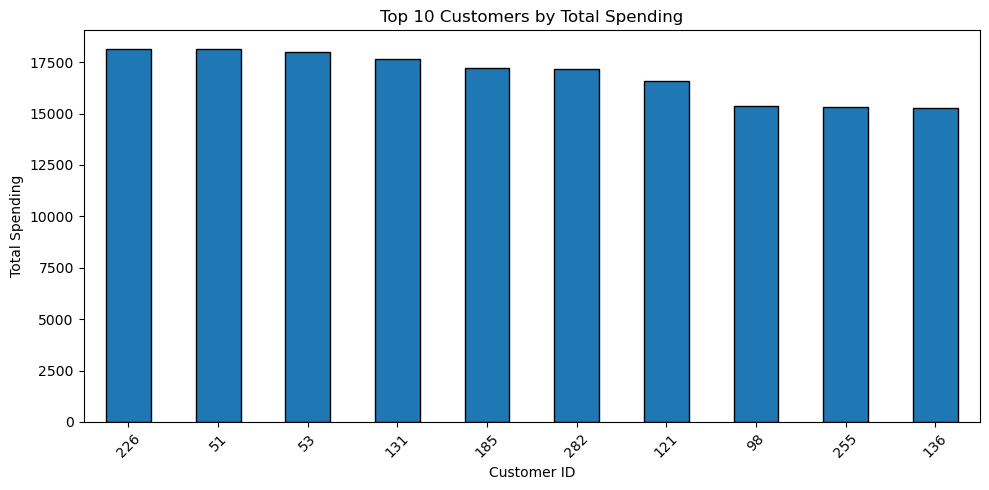

In [30]:
import matplotlib.pyplot as plt

top_10 = customer_spending.head(10)

plt.figure(figsize=(10, 5))

top_10.plot(kind="bar", edgecolor="black")

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
print("========== BUSINESS FINDINGS ==========")

print("1. Best Revenue Month:", best_month)

print("2. Lowest Revenue Month:", worst_month)

print("3. Best Product Category:", best_category)

print("4. Highest Spending Customer ID:", top_customer)

print("5. Top 10% Customer Revenue Contribution:",
      round(top_10_percentage, 2), "%")

========== BUSINESS FINDINGS ==========
1. Best Revenue Month: February
2. Lowest Revenue Month: August
3. Best Product Category: Fashion
4. Highest Spending Customer ID: 226
5. Top 10% Customer Revenue Contribution: 18.94 %


## 7. Business Recommendations

### Recommendation 1: Customer Loyalty Program
The business should introduce loyalty rewards and special discounts
for high-spending customers to encourage repeat purchases.

### Recommendation 2: Improve Product Category Sales
The business should promote popular product categories and provide
special offers for categories with lower revenue.

### Recommendation 3: Monthly Sales Campaigns
The business should analyze low-revenue months and introduce
seasonal discounts and marketing campaigns to increase sales.

# E-commerce Sales Trend Analysis – Business Report

## 1. Context
This project analyzes e-commerce sales data to understand monthly
revenue trends, product category performance, and customer spending.

The dataset contains 2,000 simulated orders from 2025.

## 2. Key Findings
- Highest revenue month: [Add your result]
- Lowest revenue month: [Add your result]
- Best-performing category: [Add your result]
- Highest-spending customer: [Add your result]
- Revenue contribution from top 10% customers: [Add your result]%

## 3. Recommendations
1. Introduce loyalty rewards for high-spending customers.
2. Improve marketing for low-performing product categories.
3. Run promotional campaigns during low-revenue months.

## 4. Next Steps
- Monitor monthly revenue.
- Analyze customer purchasing behavior.
- Track category performance.
- Evaluate the impact of marketing campaigns.

## Conclusion
This analysis helps the business understand sales performance,
identify valuable customers, and make data-driven decisions.